---
title: "Interacting Systems and Phase Transitions — Level 2"
short_title: "08 Phase Transitions"
numbering:
  heading_2: true
  equation: true
---

# Interacting Systems and Phase Transitions

:::{seealso} Math for this topic
- [M1: Vectors and ODEs](../../level2-book/math/01-vectors-odes.ipynb)
- [M6: Linear algebra](../../level2-book/math/06-linear-algebra.ipynb)
- [T-M3: Exact differentials and thermodynamic calculus](../math/03-thermodynamic-calculus.ipynb)
:::

:::{tip} Where this sits on the ladder
| Level | Text | What you do |
|---|---|---|
| 1 | — (a gap in Tipler & Mosca) | Not covered; start at Level 2 |
| **2** | **Schroeder, ch. 5 and 8** | **Ising model (1D exact, mean field), van der Waals, virial expansion** |
| 3 | Pathria, ch. 11–13 | Cluster expansions, critical exponents, the renormalization group |

The new skill at this level: adding interactions between particles, which is what makes phase transitions possible, and approximating them with a mean field

Math for this topic: mechanics M1 (Taylor series), mechanics M6 (eigenvalues, for the transfer matrix) and T-M3 (thermodynamic calculus).
:::

Workbook example ladder: van der Waals isotherms → the mean-field Ising model → scaling and critical exponents. Exercises have separate hint and answer dropdowns.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from IPython.display import Math, display
from scipy.integrate import solve_ivp, quad
from scipy.optimize import brentq

plt.rcParams.update({"figure.dpi": 110, "figure.figsize": (7, 4.6),
                     "axes.grid": True, "grid.alpha": 0.3})
k_B = 1.380649e-23     # J/K
N_A = 6.02214e23       # 1/mol
R_gas = k_B * N_A      # J/(mol K)
h = 6.62607e-34        # J s
hbar = h / (2 * np.pi)
eV = 1.602177e-19      # J
np.seterr(over="ignore", divide="ignore", invalid="ignore")   # plots hit inf at the edges; harmless here

{'divide': 'warn', 'over': 'warn', 'under': 'ignore', 'invalid': 'warn'}

## Why Interactions Matter

Every system so far has been made of independent pieces: ideal gases, independent oscillators, free electrons. Their partition functions factor, and nothing dramatic ever happens: properties change smoothly with temperature. Boiling, freezing and magnetization need particles that affect one another. The exact treatment is hard, so this chapter uses two approximate models and one exact toy.

## The van der Waals Gas

Two corrections to $PV = NkT$:

1. Molecules have size, so the free volume is $V - Nb$, with $b$ roughly a molecular volume.
2. Molecules attract weakly at a distance. Each one feels an average attraction proportional to the density $N/V$, which lowers the pressure on the walls by an amount $\propto(N/V)^2$.

$$
\left(P + \frac{aN^2}{V^2}\right)(V - Nb) = NkT .
$$ (eq-vdw)

Below a critical temperature the isotherms develop a wiggle where $\partial P/\partial V > 0$, which is unstable: compressing the fluid would lower its pressure. The **critical point** is where the wiggle first appears, $\partial P/\partial V = \partial^2P/\partial V^2 = 0$.

In [2]:
V, N, k, T, a, b_ = sp.symbols("V N k T a b", positive=True)
P = N * k * T / (V - N * b_) - a * N**2 / V**2
crit = sp.solve([sp.diff(P, V), sp.diff(P, V, 2)], [V, T], dict=True)[0]
Pc = sp.simplify(P.subs(crit))
display(Math(r"V_c = " + sp.latex(crit[V]) + r",\quad kT_c = " + sp.latex(sp.simplify(k * crit[T])) + r",\quad P_c = " + sp.latex(Pc)))
display(Math(r"\frac{P_cV_c}{NkT_c} = " + sp.latex(sp.simplify(Pc * crit[V] / (N * k * crit[T])))))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

In reduced units ($p = P/P_c$, $v = V/V_c$, $t = T/T_c$) every van der Waals gas obeys the same equation, $\left(p + 3/v^2\right)(3v - 1) = 8t$: the **law of corresponding states**. Real fluids roughly follow it (the measured $P_cV_c/NkT_c$ is near 0.29 for many gases, against the model's $3/8 = 0.375$).

### The Maxwell construction

What really happens in the wiggly region? The fluid splits into liquid and gas at a single pressure, the vapor pressure. That pressure is set by topic 5's condition that the two phases have equal Gibbs free energy, and since $dG = V\,dP$ along an isotherm, it means the integral of $V\,dP$ around the wiggle vanishes: **the two areas between the isotherm and the flat line are equal.**

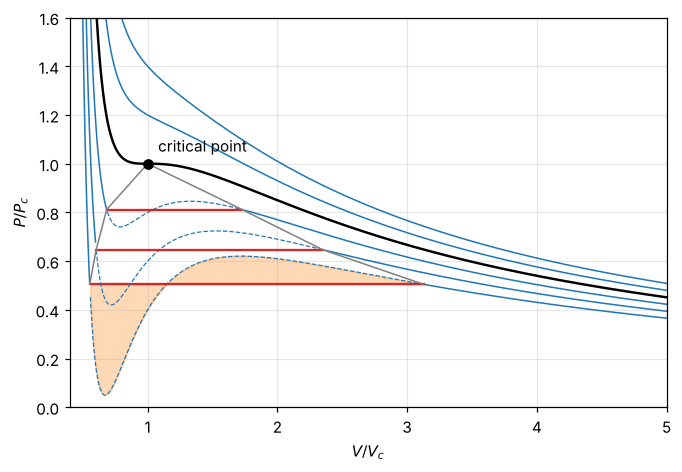

In [3]:
#| label: fig-vdw-isotherms
#| caption: "Van der Waals isotherms in reduced units for t = 0.85 to 1.1. Below t = 1 each has an unstable wiggle (dashed), replaced in reality by the flat Maxwell-construction line (red), where liquid and gas coexist; the two shaded areas are equal. The gray dome connects the coexisting liquid and gas volumes and closes at the critical point."
from scipy.optimize import fsolve
def p_vdw(v, t):
    return 8 * t / (3 * v - 1) - 3 / v**2
def maxwell(t):
    # unknowns: pressure p0, liquid volume vl, gas volume vg
    def eqs(z):
        p0, vl, vg = z
        area = (8 * t / 3) * np.log((3 * vg - 1) / (3 * vl - 1)) + 3 / vg - 3 / vl - p0 * (vg - vl)
        return [p_vdw(vl, t) - p0, p_vdw(vg, t) - p0, area]
    return fsolve(eqs, [0.6 * t**4, 0.55, 3.0])
v = np.linspace(0.45, 5, 800)
fig, ax = plt.subplots()
dome = []
for t in [0.85, 0.9, 0.95, 1.0, 1.05, 1.1]:
    p = p_vdw(v, t)
    if t < 1:
        p0, vl, vg = maxwell(t); dome.append((vl, vg, p0))
        inside = (v > vl) & (v < vg)
        ax.plot(v[~inside & (v < vl)], p[~inside & (v < vl)], color="tab:blue", lw=1)
        ax.plot(v[v > vg], p[v > vg], color="tab:blue", lw=1)
        ax.plot(v[inside], p[inside], "--", color="tab:blue", lw=0.8)
        ax.plot([vl, vg], [p0, p0], color="tab:red", lw=1.5)
        if t == 0.85:
            ax.fill_between(v[inside], p[inside], p0, color="tab:orange", alpha=0.3)
    else:
        ax.plot(v, p, color="k" if t == 1 else "tab:blue", lw=1.6 if t == 1 else 1)
d = np.array(dome)
ax.plot(np.r_[d[:, 0], 1, d[::-1, 1]], np.r_[d[:, 2], 1, d[::-1, 2]], color="gray", lw=1)
ax.plot(1, 1, "ko"); ax.text(1.08, 1.05, "critical point")
ax.set_xlim(0.4, 5); ax.set_ylim(0, 1.6); ax.set_xlabel("$V/V_c$"); ax.set_ylabel("$P/P_c$"); plt.show()

## The Virial Expansion

At low density, expand the deviation from ideal behavior in powers of $N/V$:

$$
\frac{PV}{NkT} = 1 + B_2(T)\frac NV + B_3(T)\left(\frac NV\right)^2 + \cdots
$$ (eq-virial)

$B_2$ comes from pairs of molecules, $B_3$ from triples, and so on. Expanding {eq}`eq-vdw` gives the van der Waals estimate

$$
B_2 = b - \frac{a}{kT} .
$$ (eq-b2-vdw)

At low $T$ attraction wins and $B_2 < 0$; at high $T$ the hard cores win and $B_2 > 0$. The **Boyle temperature** $kT_B = a/b$, where $B_2 = 0$, is where a real gas behaves most ideally. For the van der Waals model, $T_B = \tfrac{27}{8}T_c$.

Pathria's cluster expansion turns this into a systematic method: $B_2 = -\tfrac12\int\left(e^{-u(r)/kT} - 1\right)d^3r$ for a pair potential $u(r)$.

In [4]:
nn = sp.symbols("n", positive=True)        # n = N/V
Z_ = (1 / (1 - nn * b_) - a * nn / (k * T))      # P/(nkT) for van der Waals
series = sp.series(Z_, nn, 0, 3).removeO()
display(Math(r"\frac{PV}{NkT} = " + sp.latex(sp.collect(sp.expand(series), nn))))

<IPython.core.display.Math object>

## The Ising Model

A lattice of spins $s_i = \pm1$, each interacting with its nearest neighbors:

$$
E = -J\sum_{\langle ij\rangle}s_is_j - \mu B\sum_is_i .
$$ (eq-ising)

With $J > 0$ neighbors prefer to align (a ferromagnet). The model is a cartoon of iron, but also of a lattice gas (spin up = occupied site), a binary alloy, and much else.

### One dimension, exactly: no transition

For a ring of $N$ spins with $B = 0$, the partition function can be written as a trace of a product of $2\times2$ **transfer matrices**, $Z = \operatorname{Tr}\,\mathsf T^N$ with $\mathsf T = \begin{pmatrix}e^{\beta J} & e^{-\beta J}\\ e^{-\beta J} & e^{\beta J}\end{pmatrix}$. Its eigenvalues are $2\cosh\beta J$ and $2\sinh\beta J$ (mechanics M6), so for large $N$

$$
Z\approx(2\cosh\beta J)^N .
$$ (eq-ising-1d)

This is a smooth function of $T$ for every $T > 0$: **the 1D Ising model never magnetizes**. A single flipped domain wall costs a fixed energy $2J$ but can sit at any of $N$ places, so its entropy $k\ln N$ always wins in a long chain.

In [5]:
bJ = sp.symbols("beta_J", positive=True)
Tm = sp.Matrix([[sp.exp(bJ), sp.exp(-bJ)], [sp.exp(-bJ), sp.exp(bJ)]])
ev = [sp.simplify(e.rewrite(sp.cosh)) for e in Tm.eigenvals()]
display(Math(r"\text{eigenvalues of } \mathsf{T}: " + ",\\ ".join(sp.latex(sp.simplify(e)) for e in ev)))

<IPython.core.display.Math object>

### Mean-field theory: a transition appears

In two or three dimensions the model is hard (Onsager solved 2D exactly in 1944; 3D is unsolved). The **mean-field approximation** replaces each spin's neighbors by their average: a spin with $z$ neighbors feels an effective field from $zJ\bar s$. Then each spin is an independent two-level system (topic 6), and self-consistency demands

$$
\bar s = \tanh\!\left(\frac{zJ\bar s + \mu B}{kT}\right) .
$$ (eq-mean-field)

With $B = 0$, $\bar s = 0$ is always a solution. A nonzero solution appears when the slope of $\tanh(zJ\bar s/kT)$ at the origin exceeds 1, that is below

$$
kT_c = zJ .
$$ (eq-mean-field-tc)

Just below $T_c$, expanding $\tanh x\approx x - x^3/3$ gives $\bar s\approx\sqrt3\,(1 - T/T_c)^{1/2}$: the magnetization grows like a power of the distance from the critical point, with **critical exponent** $\beta = \tfrac12$.

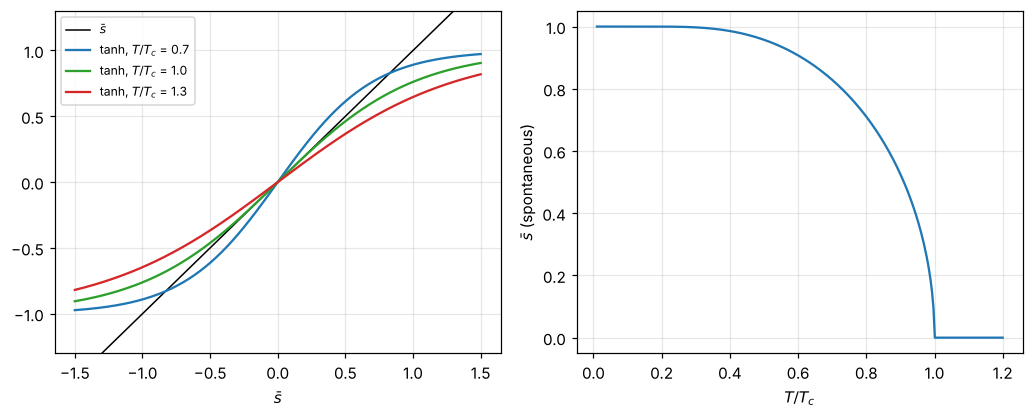

In [6]:
#| label: fig-mean-field
#| caption: "Mean-field Ising model. Left, graphical solution of s = tanh(s T_c/T) at T = 0.7 T_c, T_c and 1.3 T_c; nonzero intersections exist only below T_c. Right, the resulting spontaneous magnetization, rising like (1 − T/T_c)^(1/2) near T_c."
s = np.linspace(-1.5, 1.5, 300)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(9.5, 3.9))
a1.plot(s, s, "k", lw=1, label="$\\bar s$")
for t, col in [(0.7, "tab:blue"), (1.0, "tab:green"), (1.3, "tab:red")]:
    a1.plot(s, np.tanh(s / t), color=col, label=f"tanh, $T/T_c$ = {t}")
a1.set_xlabel("$\\bar s$"); a1.legend(fontsize=8); a1.set_ylim(-1.3, 1.3)
tt = np.linspace(0.01, 1.2, 300)
m = [brentq(lambda x: x - np.tanh(x / t), 1e-6, 1.0) if t < 0.999 else 0 for t in tt]
a2.plot(tt, m); a2.set_xlabel("$T/T_c$"); a2.set_ylabel("$\\bar s$ (spontaneous)")
plt.tight_layout(); plt.show()

### Checking mean-field theory with a simulation

The **Metropolis algorithm** samples spin configurations with the Boltzmann distribution: propose flipping a spin, accept always if it lowers $E$, otherwise with probability $e^{-\Delta E/kT}$. The figure runs it on a $40\times40$ square lattice ($z = 4$) and compares with mean field and with Onsager's exact result, $kT_c = 2J/\ln(1 + \sqrt2) = 2.269J$.

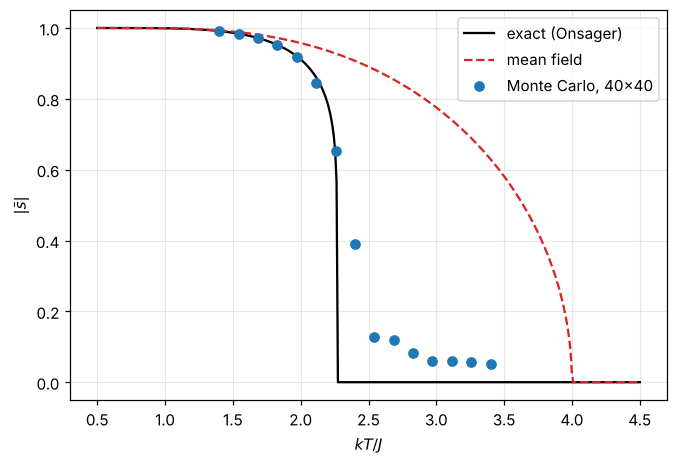

In [7]:
#| label: fig-ising-mc
#| caption: "Magnetization of the 2D Ising model on a 40 × 40 lattice from Metropolis Monte Carlo (dots), Onsager's exact result (black) and mean field (dashed). Mean field puts T_c at 4J/k, too high by 76%, because it ignores fluctuations; it also gets the exponent wrong (exact β = 1/8, so the true curve drops far more steeply). Near T_c the small lattice rounds the transition."
rng = np.random.default_rng(0)
L = 40
def sweep(S, beta):
    for parity in (0, 1):                       # checkerboard update: half the lattice at a time
        mask = (np.add.outer(np.arange(L), np.arange(L)) % 2) == parity
        nb = np.roll(S, 1, 0) + np.roll(S, -1, 0) + np.roll(S, 1, 1) + np.roll(S, -1, 1)
        dE = 2 * S * nb
        flip = mask & (rng.random((L, L)) < np.exp(-beta * dE))
        S[flip] *= -1
Ts = np.linspace(1.4, 3.4, 15)
mags = []
S = np.ones((L, L), dtype=int)
for T in Ts:
    for _ in range(300): sweep(S, 1 / T)
    acc = []
    for _ in range(400):
        sweep(S, 1 / T); acc.append(abs(S.mean()))
    mags.append(np.mean(acc))
TT = np.linspace(0.5, 4.5, 400); Tc = 2 / np.log(1 + np.sqrt(2))
exact = np.where(TT < Tc, (1 - np.sinh(2 / TT)**-4)**0.125, 0)
mf = [brentq(lambda x: x - np.tanh(4 * x / t), 1e-6, 1.0) if t < 3.999 else 0 for t in TT]
fig, ax = plt.subplots()
ax.plot(TT, exact, "k", label="exact (Onsager)"); ax.plot(TT, mf, "--", color="tab:red", label="mean field")
ax.plot(Ts, mags, "o", color="tab:blue", label="Monte Carlo, 40×40")
ax.set_xlabel("$kT/J$"); ax.set_ylabel("$|\\bar s|$"); ax.legend(); plt.show()

## Looking Ahead to Level 3

Near a critical point, quantities follow power laws: $\bar s\propto(T_c - T)^\beta$, $C\propto|T - T_c|^{-\alpha}$, susceptibility $\propto|T - T_c|^{-\gamma}$. Mean field predicts $\beta = \tfrac12$ for every system; the 2D Ising model has $\beta = \tfrac18$, the 3D Ising model and the liquid–gas critical point both have $\beta\approx0.326$. That last coincidence, **universality**, says the exponents depend only on dimension and symmetry, not on microscopic details. The **renormalization group** (Pathria 13) explains why, by watching how a system looks as you zoom out.

## Exercises

### Exercises

1. For nitrogen, $T_c = 126$ K and $P_c = 3.39$ MPa. Find the van der Waals constants $a$ and $b$ (per molecule) and the Boyle temperature.
2. Show that the van der Waals equation in reduced variables is $(p + 3/v^2)(3v - 1) = 8t$.
3. For the 1D Ising chain in zero field, find the energy per spin from {eq}`eq-ising-1d` and check its limits.
4. Expand the mean-field equation to show $\bar s\approx\sqrt{3(1 - T/T_c)}$ just below $T_c$.
5. In mean field with a small field $B$ above $T_c$, show that the susceptibility $\chi = \partial\bar s/\partial B$ diverges like $(T - T_c)^{-1}$ (the Curie–Weiss law).

:::{dropdown} Hints
1. From the SymPy cell: $kT_c = 8a/27b$ and $P_c = a/27b^2$; solve for $a$ and $b$.
2. Substitute $P = pP_c$, etc., with the critical values.
3. $\bar E = -\partial\ln Z/\partial\beta$.
4. $\tanh x\approx x - x^3/3$; divide by $\bar s\ne0$.
5. Linearize: $\bar s\approx(zJ\bar s + \mu B)/kT$.
:::

:::{dropdown} Answers
1. $b = kT_c/8P_c = 6.4\times10^{-29}$ m³, $a = 27b^2P_c = 3.8\times10^{-49}$ J·m³; $T_B = \tfrac{27}{8}T_c = 425$ K (measured: 327 K).
2. Substituting $V_c = 3Nb$, $kT_c = 8a/27b$, $P_c = a/27b^2$ and simplifying gives it.
3. $\bar E/N = -J\tanh(J/kT)$: $\to -J$ (all aligned) as $T\to0$, $\to0$ as $T\to\infty$, smooth throughout.
4. $\bar s = \bar s/t - \bar s^3/3t^3$, so $\bar s^2 = 3t^2(1 - t)\approx3(1 - t)$ with $t = T/T_c$.
5. $\bar s = \mu B/(kT - zJ) = \mu B/k(T - T_c)$, so $\chi\propto1/(T - T_c)$ (exponent $\gamma = 1$ in mean field).
:::

## Summary

- Interactions are what allow phase transitions; independent particles give only smooth behavior.
- Van der Waals: excluded volume plus mean attraction; critical point at $V_c = 3Nb$, $kT_c = 8a/27b$; Maxwell's equal-area rule gives coexistence.
- Virial expansion: $B_2 = b - a/kT$ in van der Waals; it vanishes at the Boyle temperature.
- 1D Ising: exact by transfer matrix, no transition. Mean field: $kT_c = zJ$, $\beta = \tfrac12$. Simulation and Onsager's solution show mean field overestimates $T_c$ and misses the exponents.

## Appendix: MyST patterns

Same conventions as the rest of the book: `prf:` directives for definitions, theorems and examples; `:::{dropdown}` for solutions, hints and answers; `$$ ... $$ (label)` with `` {eq}`label` `` for equations; and code cells tagged `hide-input` that start with `#| label:` and `#| caption:` lines.